In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
!pip install imbalanced-learn xgboost

In [3]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Check dataset information
print("Dataset Information:")
df.info()

# Check number of rows and columns
print("\nDataset Shape:")
print(df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

In [5]:
# Count customers in each churn category
print("Customer Churn Distribution:")
print(df['Churn'].value_counts())

# Calculate percentage
print("\nChurn Percentage:")
print(df['Churn'].value_counts(normalize=True) * 100)

Customer Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


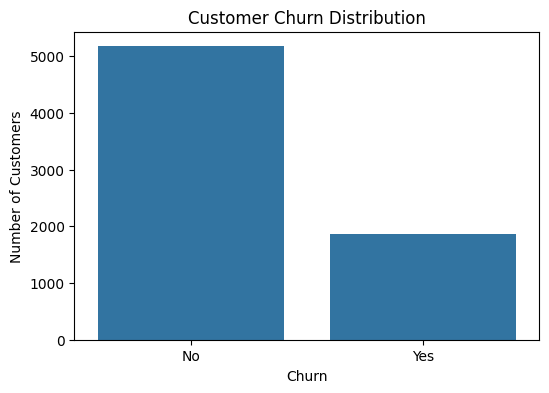

In [6]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Churn')

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [7]:
# Remove customerID column
df = df.drop('customerID', axis=1)

# Convert TotalCharges into numeric format
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check missing values
print("Missing values before handling:")
print(df.isnull().sum())

# Fill missing values with median
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

print("\nMissing values after handling:")
print(df.isnull().sum())

print("\nCleaned Dataset Shape:", df.shape)

df.head()

Missing values before handling:
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Missing values after handling:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Cleaned D

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
# Convert Churn into numeric values
df['Churn'] = df['Churn'].map({
    'No': 0,
    'Yes': 1
})

# Display churn values
print("Churn values converted successfully!")

print(df['Churn'].value_counts())

# Check data types
print("\nData Types:")
print(df.dtypes)

Churn values converted successfully!
Churn
0    5174
1    1869
Name: count, dtype: int64

Data Types:
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object


In [9]:
# Separate input features and target variable

X = df.drop('Churn', axis=1)

y = df['Churn']

print("Input Features (X) Shape:", X.shape)
print("Target Variable (y) Shape:", y.shape)

print("\nInput Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

Input Features (X) Shape: (7043, 19)
Target Variable (y) Shape: (7043,)

Input Features:
   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No   

In [10]:
from sklearn.model_selection import train_test_split

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (5634, 19)
Testing Features: (1409, 19)

Training Target: (5634,)
Testing Target: (1409,)


In [11]:
import pandas as pd

print("Training Target Distribution:")
print(y_train.value_counts())

print("\nTraining Target Percentage:")
print(y_train.value_counts(normalize=True) * 100)

Training Target Distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Training Target Percentage:
Churn
0    73.464679
1    26.535321
Name: proportion, dtype: float64


In [12]:
!pip install imbalanced-learn

In [13]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

print("\nTraining Features After SMOTE:", X_train_smote.shape)

ValueError: could not convert string to float: 'Male'

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Identify categorical and numerical columns
categorical_cols = X_train.select_dtypes(include=['object']).columns
numerical_cols = X_train.select_dtypes(exclude=['object']).columns

# Create encoder
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
        ('num', 'passthrough', numerical_cols)
    ]
)

# Transform training and testing data
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Training data shape:", X_train_encoded.shape)
print("Testing data shape:", X_test_encoded.shape)

Training data shape: (5634, 45)
Testing data shape: (1409, 45)


In [15]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_encoded, y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

print("\nTraining Features After SMOTE:", X_train_smote.shape)

Before SMOTE:
Churn
0    4139
1    1495
Name: count, dtype: int64

After SMOTE:
Churn
0    4139
1    4139
Name: count, dtype: int64

Training Features After SMOTE: (8278, 45)


In [16]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    max_depth=10
)

# Train the model
rf_model.fit(X_train_smote, y_train_smote)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [17]:
# Predict test data
y_pred_rf = rf_model.predict(X_test_encoded)

# Predict probabilities
y_prob_rf = rf_model.predict_proba(X_test_encoded)[:, 1]

print("Predictions:", y_pred_rf[:10])
print("\nProbabilities:", y_prob_rf[:10])

Predictions: [0 1 0 0 0 1 0 0 0 1]

Probabilities: [0.01421825 0.57922768 0.09103304 0.2662037  0.01846771 0.61929276
 0.26067345 0.13344756 0.01203244 0.68094295]


In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred_rf)
precision = precision_score(y_test, y_pred_rf)
recall = recall_score(y_test, y_pred_rf)
f1 = f1_score(y_test, y_pred_rf)
roc_auc = roc_auc_score(y_test, y_prob_rf)

# Display results
print("RANDOM FOREST CLASSIFICATION RESULTS")
print("------------------------------------")

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))
print("ROC-AUC Score:", round(roc_auc, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

RANDOM FOREST CLASSIFICATION RESULTS
------------------------------------
Accuracy: 0.7743
Precision: 0.5697
Recall: 0.6123
F1-Score: 0.5902
ROC-AUC Score: 0.8344

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.83      0.84      1035
           1       0.57      0.61      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.72      0.72      1409
weighted avg       0.78      0.77      0.78      1409



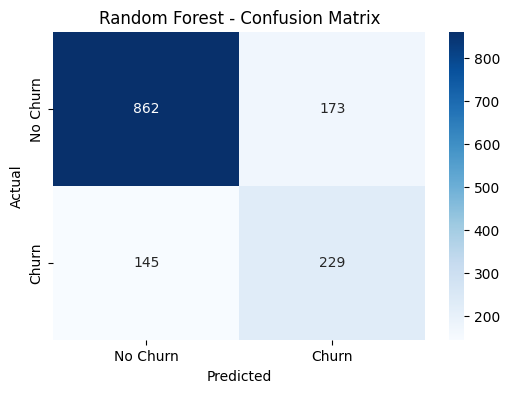

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred_rf)

# Plot confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest - Confusion Matrix')

plt.show()

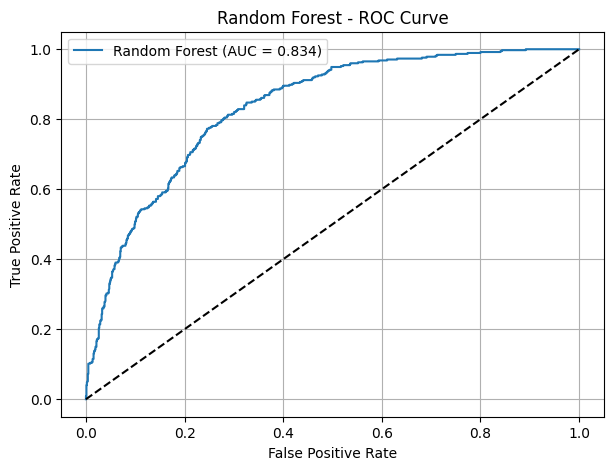

In [20]:
from sklearn.metrics import roc_curve, auc

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob_rf)

roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f'Random Forest (AUC = {roc_auc:.3f})'
)

plt.plot([0, 1], [0, 1], 'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('Random Forest - ROC Curve')

plt.legend()
plt.grid()

plt.show()

In [21]:
!pip install xgboost

In [22]:
from xgboost import XGBClassifier

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    eval_metric='logloss'
)

# Train model
xgb_model.fit(X_train_smote, y_train_smote)

print("XGBoost Model Trained Successfully!")

XGBoost Model Trained Successfully!


In [23]:
# Predict test data
y_pred_xgb = xgb_model.predict(X_test_encoded)

# Predict probabilities
y_prob_xgb = xgb_model.predict_proba(X_test_encoded)[:, 1]

print("XGBoost Predictions:")
print(y_pred_xgb[:10])

print("\nXGBoost Probabilities:")
print(y_prob_xgb[:10])

XGBoost Predictions:
[0 1 0 0 0 1 1 0 0 0]

XGBoost Probabilities:
[0.00757352 0.83272594 0.12036485 0.25501367 0.00591172 0.6397298
 0.5394026  0.07898329 0.01053297 0.46938604]


In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Calculate evaluation metrics
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)

# Display results
print("XGBOOST CLASSIFICATION RESULTS")
print("--------------------------------")

print("Accuracy:", round(accuracy_xgb, 4))
print("Precision:", round(precision_xgb, 4))
print("Recall:", round(recall_xgb, 4))
print("F1-Score:", round(f1_xgb, 4))
print("ROC-AUC Score:", round(roc_auc_xgb, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

XGBOOST CLASSIFICATION RESULTS
--------------------------------
Accuracy: 0.7949
Precision: 0.6211
Recall: 0.5829
F1-Score: 0.6014
ROC-AUC Score: 0.8424

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.87      0.86      1035
           1       0.62      0.58      0.60       374

    accuracy                           0.79      1409
   macro avg       0.74      0.73      0.73      1409
weighted avg       0.79      0.79      0.79      1409



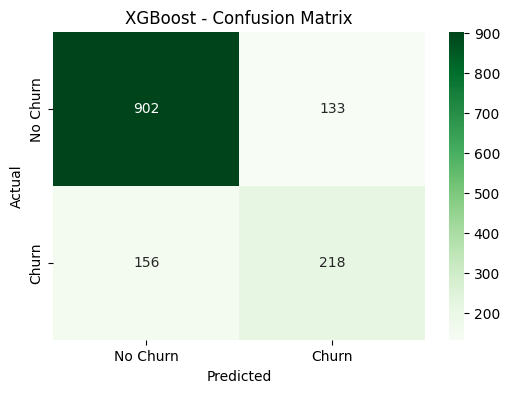

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Create confusion matrix
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

# Plot confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('XGBoost - Confusion Matrix')

plt.show()

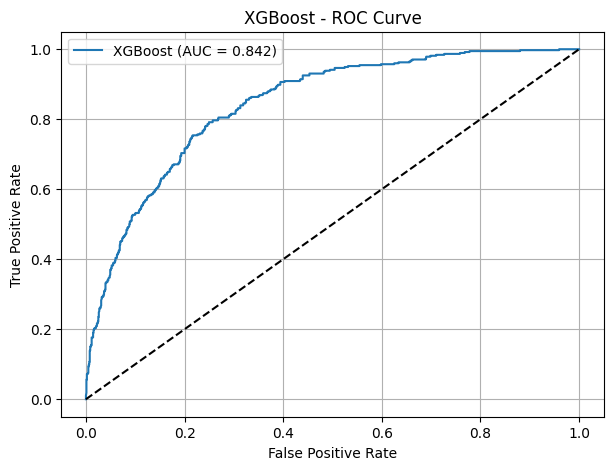

In [26]:
from sklearn.metrics import roc_curve, auc

# Calculate ROC values
fpr_xgb, tpr_xgb, thresholds_xgb = roc_curve(
    y_test, y_prob_xgb
)

roc_auc_xgb = auc(fpr_xgb, tpr_xgb)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr_xgb,
    tpr_xgb,
    label=f'XGBoost (AUC = {roc_auc_xgb:.3f})'
)

plt.plot([0, 1], [0, 1], 'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('XGBoost - ROC Curve')

plt.legend()
plt.grid()

plt.show()

In [27]:
import pandas as pd

comparison = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],
    'Accuracy': [accuracy, accuracy_xgb],
    'Precision': [precision, precision_xgb],
    'Recall': [recall, recall_xgb],
    'F1-Score': [f1, f1_xgb],
    'ROC-AUC': [roc_auc, roc_auc_xgb]
})

print("MODEL PERFORMANCE COMPARISON")
display(comparison.round(4))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.7743,0.5697,0.6123,0.5902,0.8344
1,XGBoost,0.7949,0.6211,0.5829,0.6014,0.8424


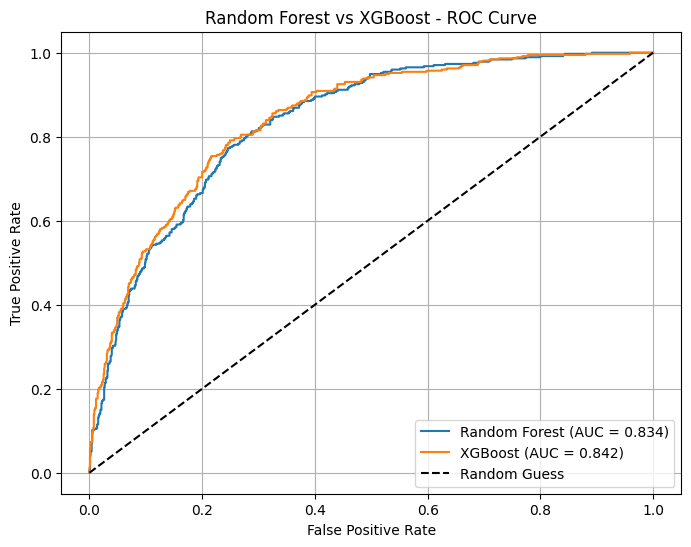

In [28]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# Random Forest ROC
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

# XGBoost ROC
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)

# Plot both curves
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_rf, tpr_rf,
    label=f'Random Forest (AUC = {roc_auc:.3f})'
)

plt.plot(
    fpr_xgb, tpr_xgb,
    label=f'XGBoost (AUC = {roc_auc_xgb:.3f})'
)

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Random Forest vs XGBoost - ROC Curve')

plt.legend()
plt.grid()
plt.show()

In [29]:
feature_names = preprocessor.get_feature_names_out()

print("Total Features:", len(feature_names))

Total Features: 45


RANDOM FOREST - TOP 10 FEATURES


,Feature,Importance
32,cat__Contract_Month-to-month,0.105001
14,cat__OnlineSecurity_No,0.093968
39,cat__PaymentMethod_Electronic check,0.089780
23,cat__TechSupport_No,0.081515
42,num__tenure,0.061109
44,num__TotalCharges,0.055352
34,cat__Contract_Two year,0.050628
17,cat__OnlineBackup_No,0.045935
12,cat__InternetService_Fiber optic,0.032701
43,num__MonthlyCharges,0.030510


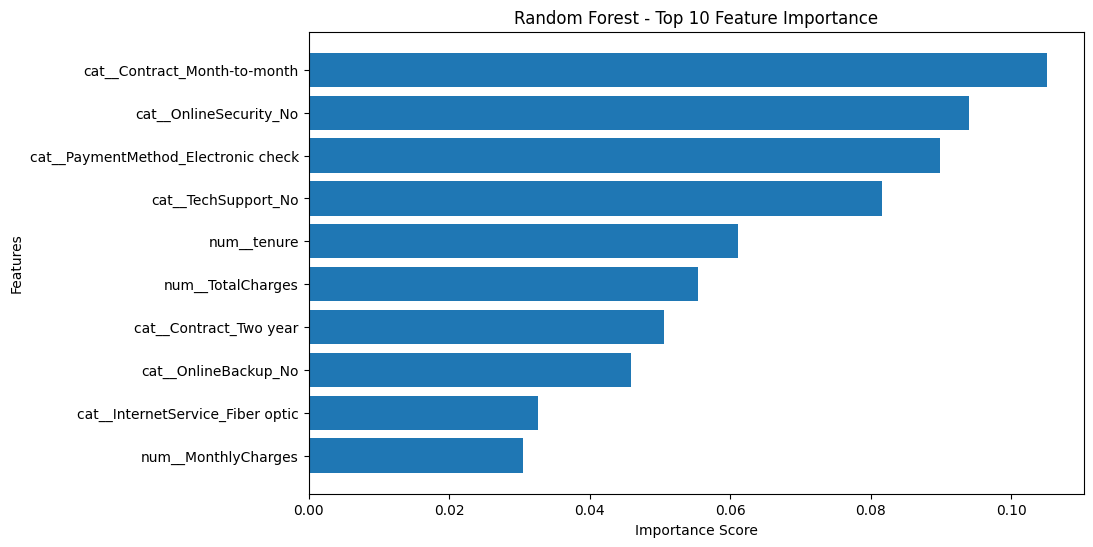

In [30]:
import pandas as pd
import matplotlib.pyplot as plt

rf_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by='Importance',
    ascending=False
).head(10)

print("RANDOM FOREST - TOP 10 FEATURES")
display(rf_importance)

plt.figure(figsize=(10, 6))

plt.barh(
    rf_importance['Feature'],
    rf_importance['Importance']
)

plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.title('Random Forest - Top 10 Feature Importance')
plt.gca().invert_yaxis()
plt.show()

XGBOOST - TOP 10 FEATURES


,Feature,Importance
32,cat__Contract_Month-to-month,0.411370
14,cat__OnlineSecurity_No,0.078101
23,cat__TechSupport_No,0.075202
39,cat__PaymentMethod_Electronic check,0.053697
12,cat__InternetService_Fiber optic,0.034624
17,cat__OnlineBackup_No,0.034354
26,cat__StreamingTV_No,0.028423
35,cat__PaperlessBilling_No,0.026144
11,cat__InternetService_DSL,0.024664
4,cat__Dependents_No,0.021421


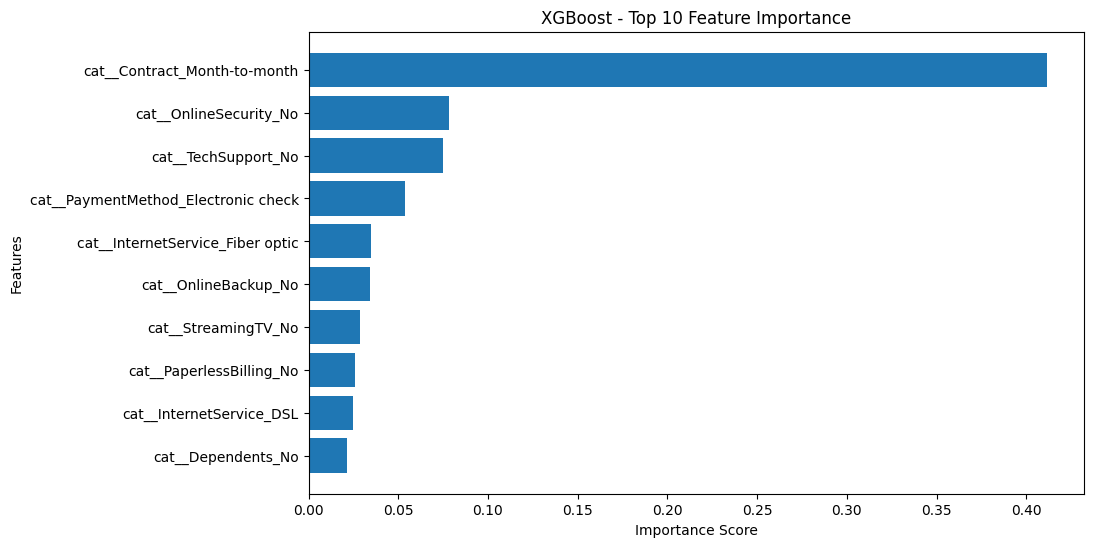

In [31]:
xgb_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by='Importance',
    ascending=False
).head(10)

print("XGBOOST - TOP 10 FEATURES")
display(xgb_importance)

plt.figure(figsize=(10, 6))

plt.barh(
    xgb_importance['Feature'],
    xgb_importance['Importance']
)

plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.title('XGBoost - Top 10 Feature Importance')
plt.gca().invert_yaxis()
plt.show()

In [32]:
from sklearn.model_selection import cross_val_score
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [33]:
rf_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        class_weight='balanced'
    ))
])

rf_cv_scores = cross_val_score(
    rf_cv_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring='roc_auc'
)

print("RANDOM FOREST 5-FOLD CROSS-VALIDATION")
print("Individual Scores:", rf_cv_scores)
print("Mean ROC-AUC:", round(rf_cv_scores.mean(), 4))
print("Standard Deviation:", round(rf_cv_scores.std(), 4))

RANDOM FOREST 5-FOLD CROSS-VALIDATION
Individual Scores: [0.85141292 0.84597006 0.84531975 0.83243662 0.82256858]
Mean ROC-AUC: 0.8395
Standard Deviation: 0.0105


In [34]:
xgb_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=5,
        random_state=42,
        eval_metric='logloss'
    ))
])

xgb_cv_scores = cross_val_score(
    xgb_cv_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring='roc_auc'
)

print("XGBOOST 5-FOLD CROSS-VALIDATION")
print("Individual Scores:", xgb_cv_scores)
print("Mean ROC-AUC:", round(xgb_cv_scores.mean(), 4))
print("Standard Deviation:", round(xgb_cv_scores.std(), 4))

XGBOOST 5-FOLD CROSS-VALIDATION
Individual Scores: [0.85778077 0.85222481 0.84471588 0.83143288 0.82240884]
Mean ROC-AUC: 0.8417
Standard Deviation: 0.0131


In [35]:
final_results = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],
    'Test ROC-AUC': [roc_auc, roc_auc_xgb],
    'CV Mean ROC-AUC': [
        rf_cv_scores.mean(),
        xgb_cv_scores.mean()
    ],
    'CV Std': [
        rf_cv_scores.std(),
        xgb_cv_scores.std()
    ]
})

display(final_results.round(4))

# Identify the best model based on test ROC-AUC
if roc_auc > roc_auc_xgb:
    print("Best Model: Random Forest")
else:
    print("Best Model: XGBoost")

,Model,Test ROC-AUC,CV Mean ROC-AUC,CV Std
0,Random Forest,0.8344,0.8395,0.0105
1,XGBoost,0.8424,0.8417,0.0131


Best Model: XGBoost


In [36]:
print("=" * 55)
print("PREDICTIVE CUSTOMER CHURN CLASSIFIER")
print("=" * 55)

print("\nAlgorithms Used:")
print("1. Random Forest")
print("2. XGBoost")

print("\nData Balancing:")
print("SMOTE")

print("\nEvaluation Metrics:")
print("Accuracy")
print("Precision")
print("Recall")
print("F1-Score")
print("ROC-AUC")

print("\nCross Validation:")
print("5-Fold Cross Validation")

print("\nFinal ROC-AUC Results:")
print("Random Forest:", round(roc_auc, 4))
print("XGBoost:", round(roc_auc_xgb, 4))

print("\nProject Completed Successfully!")

PREDICTIVE CUSTOMER CHURN CLASSIFIER

Algorithms Used:
1. Random Forest
2. XGBoost

Data Balancing:
SMOTE

Evaluation Metrics:
Accuracy
Precision
Recall
F1-Score
ROC-AUC

Cross Validation:
5-Fold Cross Validation

Final ROC-AUC Results:
Random Forest: 0.8344
XGBoost: 0.8424

Project Completed Successfully!
